teh_045.png {'rerata': 128.8, 'simpangan_baku': 58.1, 'min': 19, 'maks': 247, 'persen_gelap': 3.7, 'persen_terang': 13.8}


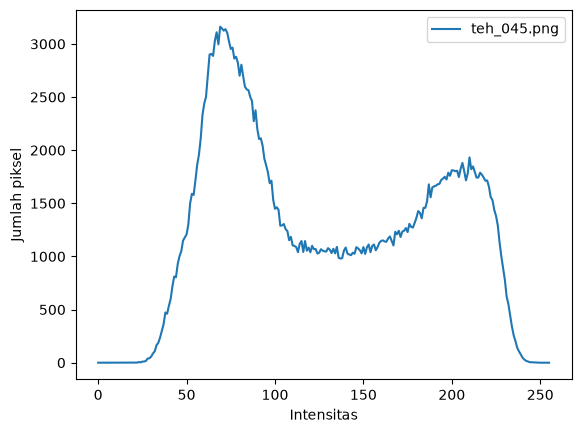

In [3]:
import sys
import os
import cv2
import numpy as np

sys.path.append(os.path.abspath("../src"))

from utils_cv import baca, statistik, kontras_bercak, tampil
import matplotlib.pyplot as plt

for nama in ["teh_041.png", "teh_042.png", "teh_043.png",
"teh_044.png", "teh_045.png"]:
    gray = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"), cv2.COLOR_BGR2GRAY)
print(nama, statistik(gray))
hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
plt.plot(hist, label=nama)
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend()
plt.savefig("../hasil/b3_histogram_5kondisi.png")

In [4]:
import cv2
import numpy as np

nama = "teh_045.png"  # kondisi bayangan
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)


rmin, rmax = np.percentile(gray, (2, 98))  # abaikan 2% piksel ekstrem

hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip(
        (gray - rmin) / (rmax - rmin) * 255, 0, 255
    ).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(
        clipLimit=2.0, tileGridSize=(8, 8)
    ).apply(gray),
}

for nm, c in hasil.items():
    print(
        f"{nm:10s} KB={kontras_bercak(c, md, mb):.2f} "
        f"sigma={c.std():.1f}"
    )

asli       KB=0.80 sigma=58.1
negatif    KB=0.80 sigma=58.1
cerah+50   KB=0.80 sigma=55.4
kontras    KB=0.80 sigma=80.3
regang     KB=0.82 sigma=81.0
gamma0.5   KB=0.73 sigma=41.7
gamma1.8   KB=0.91 sigma=63.2
ekualisasi KB=0.71 sigma=73.4
CLAHE      KB=1.46 sigma=47.7


clip=1.0 tile=4: KB=1.60
clip=1.0 tile=8: KB=1.36
clip=1.0 tile=16: KB=1.24
clip=2.0 tile=4: KB=1.80
clip=2.0 tile=8: KB=1.46
clip=2.0 tile=16: KB=1.21
clip=4.0 tile=4: KB=1.74
clip=4.0 tile=8: KB=1.34
clip=4.0 tile=16: KB=1.26


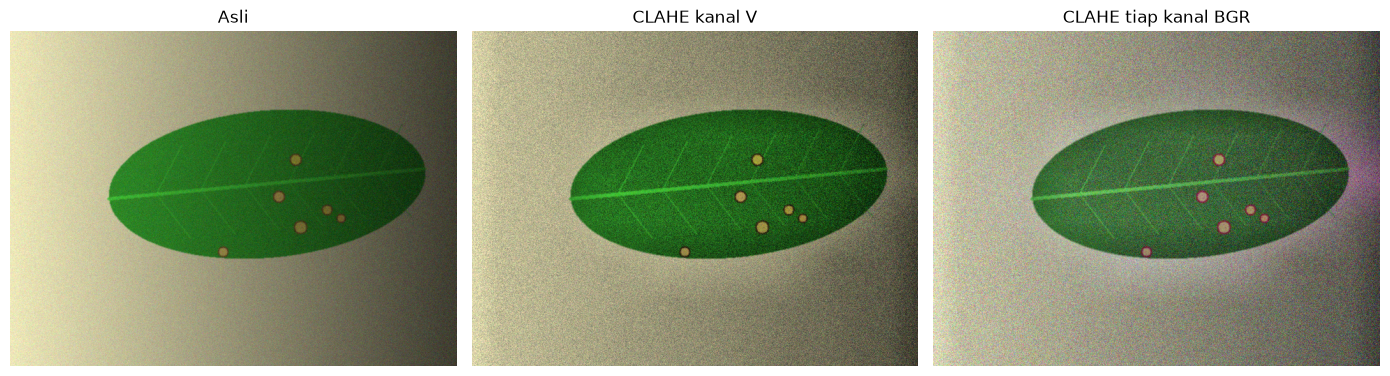

In [5]:
# eksperimen parameter CLAHE
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip,
                            tileGridSize=(tile, tile)).apply(gray)
        print(f"clip={clip} tile={tile}: KB={kontras_bercak(c, md, mb):.2f}")

# CLAHE pada citra warna: kanal V (benar) dan tiap kanal BGR (bandingkan)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"])